In [1]:
import pandas as pd
import numpy as np
df = pd.read_csv("netflix_titles.csv")
df.head()


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [2]:
df.describe()

,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [4]:
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df[df.duplicated()]

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description


In [7]:
df["type"].unique()
df["rating"].unique()
df["country"].nunique()

748

In [8]:
df["rating"].unique()


array(['PG-13', 'TV-MA', 'PG', 'TV-14', 'TV-PG', 'TV-Y', 'TV-Y7', 'R',
       'TV-G', 'G', 'NC-17', '74 min', '84 min', '66 min', 'NR', nan,
       'TV-Y7-FV', 'UR'], dtype=object)

In [9]:
df.dtypes

show_id         object
type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
description     object
dtype: object

In [10]:
(df.isnull().sum()/len(df) * 100).round(2)

show_id          0.00
type             0.00
title            0.00
director        29.91
cast             9.37
country          9.44
date_added       0.11
release_year     0.00
rating           0.05
duration         0.03
listed_in        0.00
description      0.00
dtype: float64

In [11]:
# 1. Get all rows where cast is null
df["cast"] = df["cast"].fillna("Not specified")
df["country"] = df["country"].fillna("Not specified")
df["director"] = df["director"].fillna("unknown")


In [12]:
df.loc[df["director"].isnull(), ["title","type", "release_year", "country"]].head(10)

,title,type,release_year,country


In [13]:
df_clean = df.copy()

In [14]:
df


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Not specified,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Not specified,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,unknown,Not specified,Not specified,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
...,...,...,...,...,...,...,...,...,...,...,...,...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,unknown,Not specified,Not specified,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."


In [15]:
df_clean.isnull().sum()

show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           4
duration         3
listed_in        0
description      0
dtype: int64

In [16]:
df_clean["director"]= df_clean["director"].fillna("unknown")
df_clean["cast"]= df_clean["cast"].fillna("unknown")
df_clean["country"]= df_clean["country"].fillna("unknown")

In [17]:
df_clean.isnull().sum()

show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           4
duration         3
listed_in        0
description      0
dtype: int64

In [18]:
movie_serie_ratio = df_clean["type"].value_counts()
print(movie_serie_ratio)
print(movie_serie_ratio["Movie"])

type
Movie      6131
TV Show    2676
Name: count, dtype: int64
6131


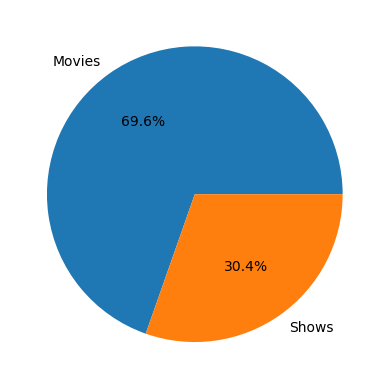

In [19]:
import matplotlib.pyplot as plt
a = movie_serie_ratio["Movie"]
b  = movie_serie_ratio["TV Show"]
plt.pie([a,b], labels=["Movies","Shows"], autopct="%1.1f%%")
plt.show()



In [20]:
df_clean.groupby(["release_year", "type"]).size().unstack(fill_value=0)

type,Movie,TV Show
release_year,,
1925,0,1
1942,2,0
1943,3,0
1944,3,0
1945,3,1
...,...,...
2017,767,265
2018,767,380
2019,633,397


In [21]:
df_clean[["date_added","title"]].head(10)

,date_added,title
0,"September 25, 2021",Dick Johnson Is Dead
1,"September 24, 2021",Blood & Water
2,"September 24, 2021",Ganglands
3,"September 24, 2021",Jailbirds New Orleans
4,"September 24, 2021",Kota Factory
5,"September 24, 2021",Midnight Mass
6,"September 24, 2021",My Little Pony: A New Generation
7,"September 24, 2021",Sankofa
8,"September 24, 2021",The Great British Baking Show
9,"September 24, 2021",The Starling


In [22]:
df_clean[["date_added","title","type","release_year"]].head(10).sort_values("release_year")

,date_added,title,type,release_year
7,"September 24, 2021",Sankofa,Movie,1993
0,"September 25, 2021",Dick Johnson Is Dead,Movie,2020
2,"September 24, 2021",Ganglands,TV Show,2021
1,"September 24, 2021",Blood & Water,TV Show,2021
3,"September 24, 2021",Jailbirds New Orleans,TV Show,2021
4,"September 24, 2021",Kota Factory,TV Show,2021
5,"September 24, 2021",Midnight Mass,TV Show,2021
6,"September 24, 2021",My Little Pony: A New Generation,Movie,2021
8,"September 24, 2021",The Great British Baking Show,TV Show,2021
9,"September 24, 2021",The Starling,Movie,2021


In [23]:
df_clean["date_added"] = pd.to_datetime(df["date_added"],format="mixed", errors="coerce")


In [24]:
df_clean["date_added"].isnull().sum()

np.int64(10)

In [25]:
df_clean.dtypes

show_id                 object
type                    object
title                   object
director                object
cast                    object
country                 object
date_added      datetime64[ns]
release_year             int64
rating                  object
duration                object
listed_in               object
description             object
dtype: object

In [26]:
df_clean["year_added"] = df_clean["date_added"].dt.year
yearly_additions = (df_clean.groupby(["year_added", "type"]).size().unstack(fill_value=0))
yearly_additions

type,Movie,TV Show
year_added,,
2008.0,1,1
2009.0,2,0
2010.0,1,0
2011.0,13,0
2012.0,3,0
2013.0,6,5
2014.0,19,5
2015.0,56,26
2016.0,253,176


In [27]:
df_clean.isnull().sum()

show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           4
duration         3
listed_in        0
description      0
year_added      10
dtype: int64

In [28]:
df.loc[df["date_added"].notnull(), "date_added"].head(15)

0     September 25, 2021
1     September 24, 2021
2     September 24, 2021
3     September 24, 2021
4     September 24, 2021
5     September 24, 2021
6     September 24, 2021
7     September 24, 2021
8     September 24, 2021
9     September 24, 2021
10    September 24, 2021
11    September 23, 2021
12    September 23, 2021
13    September 22, 2021
14    September 22, 2021
Name: date_added, dtype: object

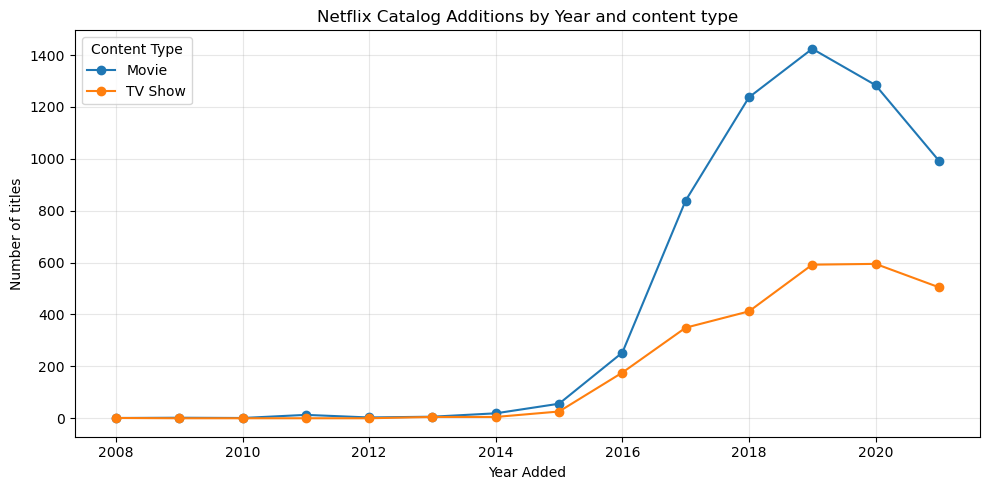

In [29]:
import matplotlib.pyplot as plt
yearly_additions.plot(kind="line", marker="o", figsize=(10, 5))
plt.title("Netflix Catalog Additions by Year and content type")
plt.xlabel("Year Added")
plt.ylabel("Number of titles")
plt.legend(title="Content Type")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
tv_show_share = (yearly_additions["TV Show"]/ yearly_additions.sum(axis=1) * 100)
tv_show_share.round(2)

year_added
2008.0    50.00
2009.0     0.00
2010.0     0.00
2011.0     0.00
2012.0     0.00
2013.0    45.45
2014.0    20.83
2015.0    31.71
2016.0    41.03
2017.0    29.38
2018.0    24.98
2019.0    29.37
2020.0    31.67
2021.0    33.71
dtype: float64

In [31]:
df_clean["rating"]

0       PG-13
1       TV-MA
2       TV-MA
3       TV-MA
4       TV-MA
        ...  
8802        R
8803    TV-Y7
8804        R
8805       PG
8806    TV-14
Name: rating, Length: 8807, dtype: object

In [32]:
df_clean["rating"].value_counts()

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64

In [33]:
rating_counts = df_clean["rating"].value_counts()
rating_share = (rating_counts / len(df_clean)) * 100

rating_share.round(2)

rating
TV-MA       36.41
TV-14       24.53
TV-PG        9.80
R            9.07
PG-13        5.56
TV-Y7        3.79
TV-Y         3.49
PG           3.26
TV-G         2.50
NR           0.91
G            0.47
TV-Y7-FV     0.07
NC-17        0.03
UR           0.03
74 min       0.01
84 min       0.01
66 min       0.01
Name: count, dtype: float64

In [34]:
df_clean["country"].value_counts().head(20)

country
United States                    2818
India                             972
Not specified                     831
United Kingdom                    419
Japan                             245
South Korea                       199
Canada                            181
Spain                             145
France                            124
Mexico                            110
Egypt                             106
Turkey                            105
Nigeria                            95
Australia                          87
Taiwan                             81
Indonesia                          79
Brazil                             77
Philippines                        75
United Kingdom, United States      75
United States, Canada              73
Name: count, dtype: int64

In [35]:
df_clean.isnull().sum()


show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           4
duration         3
listed_in        0
description      0
year_added      10
dtype: int64

In [36]:
df_clean["release_decade"] = (df_clean["release_year"] // 10) * 10

df_clean["release_decade"].value_counts().sort_index()

release_decade
1920       1
1940      15
1950      11
1960      25
1970      70
1980     129
1990     274
2000     810
2010    5927
2020    1545
Name: count, dtype: int64

In [37]:
df_clean.loc[df_clean["type"] == "Movie", "duration"].value_counts().head(15)

duration
90 min     152
97 min     146
94 min     146
93 min     146
91 min     144
95 min     137
96 min     130
92 min     129
102 min    122
98 min     120
99 min     118
88 min     116
101 min    116
103 min    114
106 min    111
Name: count, dtype: int64

In [38]:
df_clean['duration_min']=df_clean['duration'].str.split(' ').str[0]


In [39]:
df_clean['movie_duration'] = df_clean.loc[df_clean['type'] == 'Movie', 'duration_min']

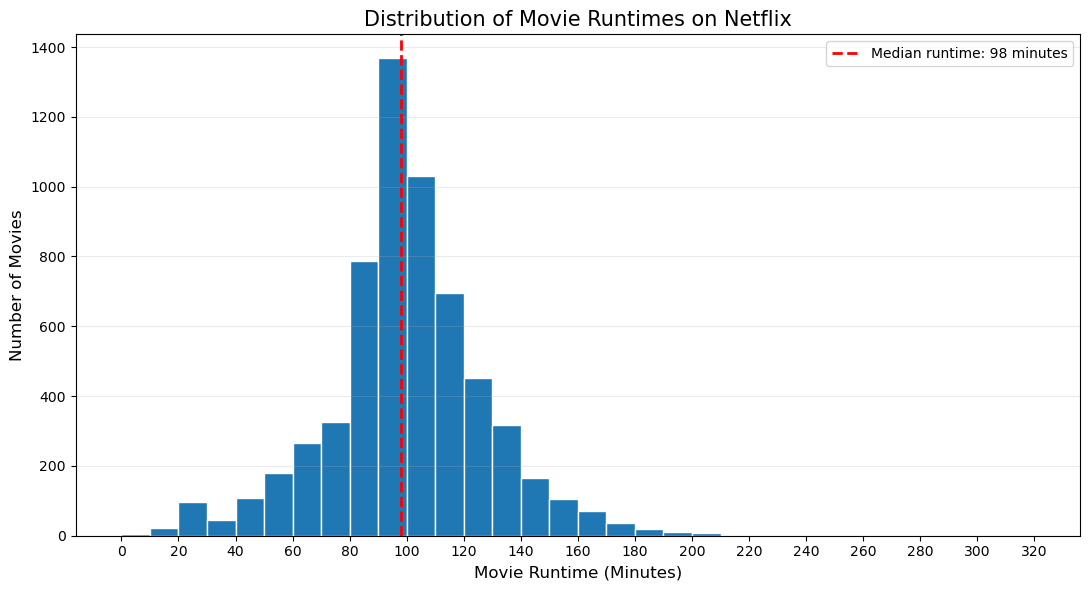

In [40]:
movie_duration = df_clean["movie_duration"].dropna().astype(int)

plt.figure(figsize=(11, 6))

plt.hist(
    movie_duration,
    bins=range(0, movie_duration.max() + 11, 10),
    edgecolor="white"
)

median = movie_duration.median()

plt.axvline(
    median,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Median runtime: {median:.0f} minutes"
)

plt.title("Distribution of Movie Runtimes on Netflix", fontsize=15)
plt.xlabel("Movie Runtime (Minutes)", fontsize=12)
plt.ylabel("Number of Movies", fontsize=12)

plt.xticks(range(0, int(movie_duration.max()) + 20, 20))
plt.grid(axis="y", alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

### Movie Runtime Distribution
The distribution shows that Netflix's movie catalogue is heavily concentrated around the 80–110 minute range, with a median runtime of 98 minutes. The frequency of movies gradually decreases as runtimes increase beyond this range, indicating that longer movies are less common in the catalogue.

Overall, the distribution suggests that feature-length movies around 90–100 minutes are particularly well represented in this dataset.

In [48]:
df_clean['show_duration'] = df_clean.loc[df_clean['type'] == 'TV Show', 'duration_min']
show_duration = df_clean["show_duration"]

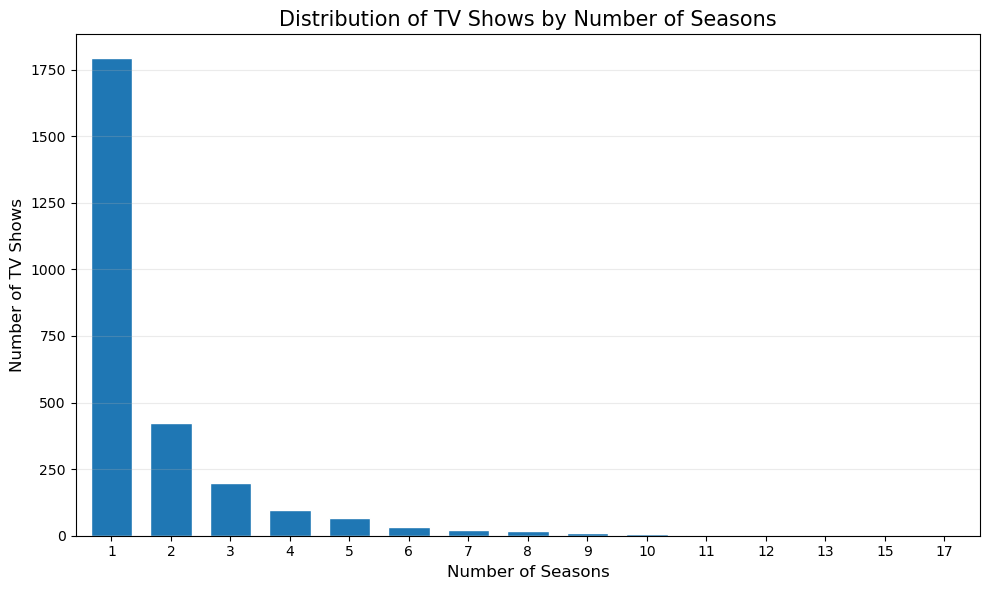

In [49]:
show_counts = show_duration.dropna().astype(int).value_counts().sort_index()

plt.figure(figsize=(10, 6))

show_counts.plot(
    kind="bar",
    edgecolor="white",
    width=0.7
)

plt.title("Distribution of TV Shows by Number of Seasons", fontsize=15)
plt.xlabel("Number of Seasons", fontsize=12)
plt.ylabel("Number of TV Shows", fontsize=12)

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

###### TV Show Season Distribution

The distribution indicates that Netflix's TV Show catalogue is heavily concentrated in shorter series. Shows with one season account for the largest share, followed by two-season shows. The number of titles decreases considerably as the season count increases, while long-running series with seven or more seasons are relatively uncommon.

This suggests that shorter TV series are much more prevalent in the catalogue than long-running shows.

<Axes: xlabel='listed_in'>

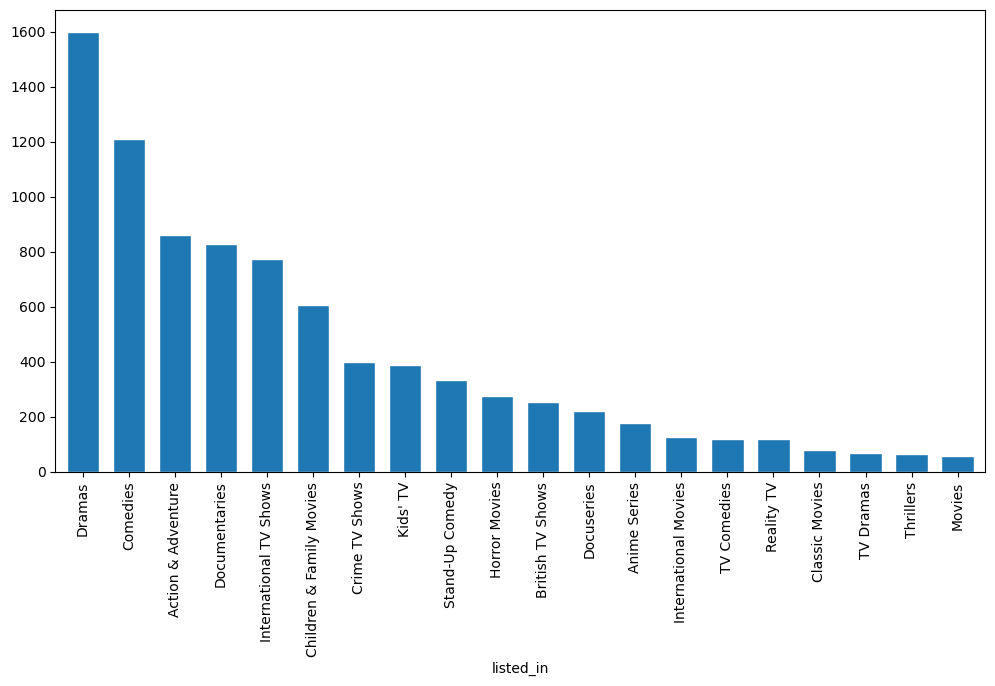

In [ ]:
genre_counts = df_clean["listed_in"].str.split(", ").str[0].value_counts()
genre_counts.head(20).plot(kind="bar", figsize=(12, 6), edgecolor="white", width=0.7)

###### Netflix Catalogue Category Distribution

The catalogue is heavily represented by International Movies, followed by Dramas and Comedies. International TV Shows also account for a substantial number of titles. Documentaries and Action & Adventure are among the other frequently represented categories.

This indicates a broad catalogue covering multiple content categories, with particularly strong representation of international content and drama-related titles.

**Note:** Individual titles can belong to multiple categories, so category counts are not mutually exclusive.